# Phase 1: Exploratory Data Analysis (EDA)

In this notebook, we will analyze the SemEval 2014 Task 4 (Restaurant & Laptop) datasets.

We will explore:
1. Total number of samples
2. Aspect frequency
3. Sentiment class distribution
4. Sentence length distributions

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

DATA_DIR = "../data/processed"
files = [f for f in os.listdir(DATA_DIR) if f.endswith('.csv')]
print(f"Found datasets: {files}")


Found datasets: ['baseline_results.csv', 'Laptops_Test.csv', 'Laptops_Train.csv', 'Restaurants_Test.csv', 'Restaurants_Train.csv']


In [2]:
dfs = []
for f in files:
    df = pd.read_csv(os.path.join(DATA_DIR, f))
    df['source'] = f.replace('.csv', '')
    dfs.append(df)
    
df_all = pd.concat(dfs, ignore_index=True)
print(f"Total aspect annotations: {len(df_all)}")
df_all.head()

Total aspect annotations: 7706


,Model,Accuracy,Macro F1,Training Time (s),source,text,aspect,sentiment,from,to
0,TF-IDF + Logistic Regression,0.707523,0.656882,2.004918,baseline_results,NaN,NaN,NaN,NaN,NaN
1,TF-IDF + SVM,0.716822,0.656143,0.791124,baseline_results,NaN,NaN,NaN,NaN,NaN
2,BiLSTM,0.688926,0.603736,79.256219,baseline_results,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,Laptops_Test,"Boot time is super fast, around anywhere from ...",Boot time,NaN,0.0,9.0
4,NaN,NaN,NaN,NaN,Laptops_Test,tech support would not fix the problem unless ...,tech support,NaN,0.0,12.0


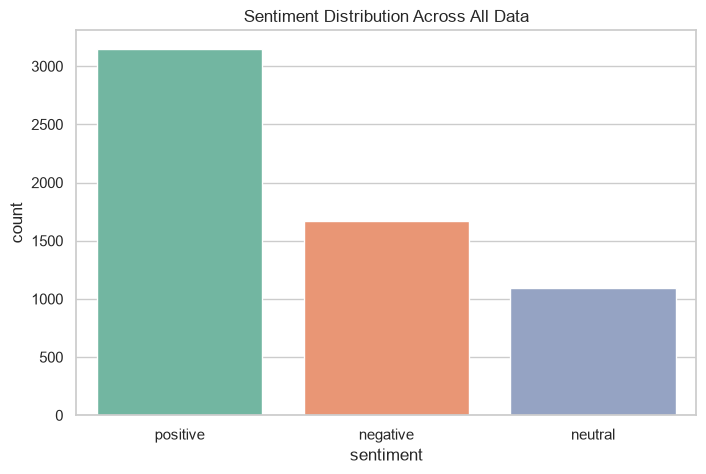

In [3]:
# 1. Sentiment Distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df_all, x='sentiment', order=['positive', 'negative', 'neutral'], palette='Set2')
plt.title('Sentiment Distribution Across All Data')
plt.show()

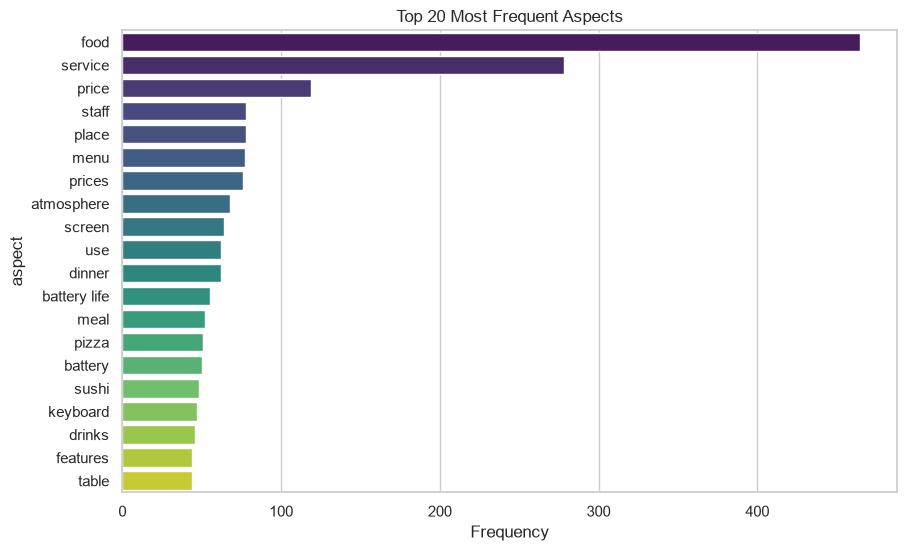

In [4]:
# 2. Top 20 Aspects
plt.figure(figsize=(10, 6))
top_aspects = df_all['aspect'].value_counts().head(20)
sns.barplot(x=top_aspects.values, y=top_aspects.index, palette='viridis')
plt.title('Top 20 Most Frequent Aspects')
plt.xlabel('Frequency')
plt.show()

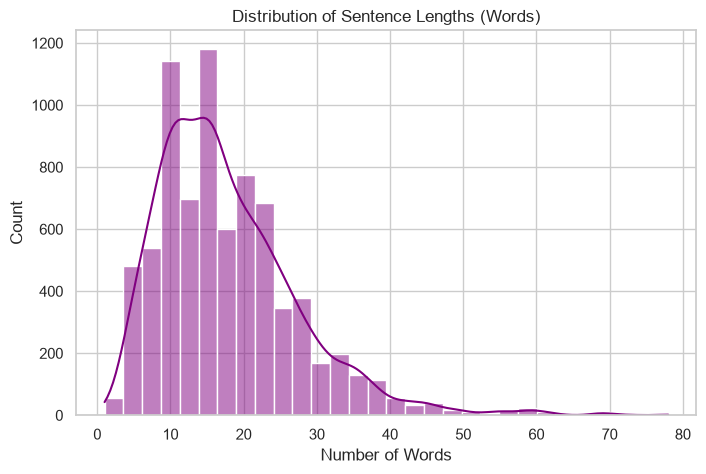

In [5]:
# 3. Sentence Length Distribution
df_all['sentence_length'] = df_all['text'].apply(lambda x: len(str(x).split()))
plt.figure(figsize=(8, 5))
sns.histplot(df_all['sentence_length'], bins=30, kde=True, color='purple')
plt.title('Distribution of Sentence Lengths (Words)')
plt.xlabel('Number of Words')
plt.show()

In [6]:
# Save EDA summary statistics to a text file
with open('../data/processed/eda_summary.txt', 'w') as f:
    f.write(f"Total Annotations: {len(df_all)}\n")
    f.write(f"Total Sentences (Unique): {df_all['text'].nunique()}\n")
    f.write(f"Sentiment Counts:\n{df_all['sentiment'].value_counts()}\n")
    f.write(f"Average Sentence Length: {df_all['sentence_length'].mean():.2f} words\n")
